Compare fitness model with neutral model (fixed transmissibility)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

import covasim as cv
from Bio import SeqIO
import networkx as nx
from scipy.stats import linregress, t as t_dist

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from covasim.jhk_covasim4wastewater.intervention_search.simulation.runner import run_evo_simulation
from covasim.jhk_covasim4wastewater.intervention_search.analysis.mutation_tree import build_mutation_tree, build_infection_seq_tree, extract_sequenced_subtree, add_internal_leaves, mutation_tree_to_newick, export_fasta_from_G, set_all_branch_lengths_to_one
from covasim.jhk_covasim4wastewater.intervention_search.plotting.plot_mutation_tree import plot_mutation_tree, plot_erase_mutation_tree, plot_phylo_tree

from covasim.inference import Inference

Covasim 3.1.8 (2026-05-29) — © 2020-2026 by IDM


In [2]:
REF_FASTA     = '../sars-2-data/NC_045512_Hu-1.fasta'
FITNESS_CSV   = '../../../data/nt_fitness.csv'

In [3]:
def get_mutation_in_long_df_full_tree(mutation_nodes):
    rows = []
    for mutation_state, node in mutation_nodes.items():
        if not mutation_state:
            rows.append({"node": node, "mutation": None})
        for site, ref, alt in mutation_state:
            rows.append({"node": node, "mutation": cv.decode_sequence([ref])+str(int(site)+1)+cv.decode_sequence([alt])})
    df = pd.DataFrame(rows)
    df = df.dropna()
    return df

def get_mutation_in_long_df_inferred_tree(nodes_mutation):
    rows = []
    for node, mutation_state in nodes_mutation.items():
        if not mutation_state:
            rows.append({"node": node, "mutation": None})
        for site, ref, alt in mutation_state:
            rows.append({"node": node, "mutation": ref+str(site)+alt}) # this is already 1-based idx
    df = pd.DataFrame(rows)
    df = df.dropna()
    return df

def plot_mut_occurrence(df):
    mutation_counts = df["mutation"].value_counts()  # counts per individual mutation in full transmission tree
    n_dist = mutation_counts.value_counts().sort_index()  # index = n, values = number of mutations occurring n times

    _, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(n_dist.index, n_dist.values, color="#2a78d6", s=80, zorder=3)
    
    ax.set_xlabel("Number of occurrences (n)")
    ax.set_ylabel("Number of mutations")
    ax.set_title("Distribution of mutation occurrence counts")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.set_xlim(0, n_dist.index.max() + 1)
    ax.set_ylim(0, n_dist.values.max() + 2)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    
    plt.tight_layout()
    plt.show()

def get_fitness():
    fitness = pd.read_csv(FITNESS_CSV)
    ref = SeqIO.read(REF_FASTA, format="fasta")
    def get_ref_nt(nt_site):
        return str(ref.seq)[nt_site-1]
    fitness["ref"] = fitness["nt_site"].apply(lambda x: get_ref_nt(x))
    assert (fitness.loc[(fitness["ref"] == fitness["nt"]) & (fitness["nt_differs_among_clade_founders"] == False), "fitness"] == 0).all()

    # some variant with ref == alt has non-zero fitness value, drop them here
    fitness = fitness[fitness["nt"] != fitness["ref"]]
    fitness["mutation"] = fitness["ref"] + fitness["nt_site"].astype(str) + fitness["nt"]
    fitness_mapping = dict(zip(fitness["mutation"], fitness["fitness"]))
    return fitness_mapping

def compute_node_stats(h_tree, mutation_nodes, node_events):
    fitness_mapping = get_fitness()
    rows = []
    for mutation_state, node in mutation_nodes.items():
        if not mutation_state:
            rows.append({"node": node, "mutation": None})
        for site, ref, alt in mutation_state:
            rows.append({"node": node, "mutation": cv.decode_sequence([ref])+str(int(site)+1)+cv.decode_sequence([alt])})
    df = pd.DataFrame(rows)
    df = df.dropna()

    # calculate the sum of fitness value for each node (mutation state)
    df["fitness"] = df["mutation"].map(fitness_mapping).fillna(0)
    stats = df.groupby("node", as_index=False)["fitness"].sum()

    internal_nodes = [n for n in h_tree.nodes if h_tree.out_degree(n) > 0]
    n_descendants = {n: len(nx.descendants(h_tree, n)) for n in internal_nodes} # exclude the tips - they have no descdents

    earliest_infection_day = {node: min(int(e.rsplit("_", 1)[1]) for e in events) for node, events in node_events.items() if events}
    n_infection_times = {node: len(events) for node, events in node_events.items() if events}

    stats["n_descendants"] = stats["node"].map(n_descendants)
    stats["earliest_infection_day"] = stats["node"].map(earliest_infection_day)
    stats["n_infection_times"] = stats["node"].map(n_infection_times)
    stats = stats.dropna(subset=["fitness", "n_descendants"])

    # rm the node which was reinfected too many times
    # stats = stats[stats["n_infection_times"] <= 30]
    return stats

def plot_rt(sim):
    r = sim.compute_r_eff(method='daily', smoothing=0)
    _, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(len(r)), r, marker="o")
    ax.set_xlabel("day")
    ax.set_ylabel("Rt from sim")
    ax.set_title("Rt per day")
    plt.show()

def plot_ndesc_vs_fitness(node_stats):
    _, ax = plt.subplots(figsize=(7, 5))
    x = node_stats["fitness"].to_numpy(dtype=float)
    y = node_stats["n_descendants"].to_numpy(dtype=float)

    ax.scatter(x, y, color="#2a78d6", s=80, alpha=0.5, zorder=3)

    # regression line (least squares) with 95% CI of the fit
    res = linregress(x, y)
    xs = np.linspace(x.min(), x.max(), 200)
    yhat = res.slope * xs + res.intercept

    n = len(x)
    resid = y - (res.slope * x + res.intercept)
    s_err = np.sqrt(np.sum(resid**2) / (n - 2))
    t = t_dist.ppf(0.975, n - 2)
    ci = t * s_err * np.sqrt(1 / n + (xs - x.mean())**2 / np.sum((x - x.mean())**2))

    ax.fill_between(xs, yhat - ci, yhat + ci, color="#d62728", alpha=0.4, lw=0, zorder=2,
                    label="95% CI")
    ax.plot(xs, yhat, color="#d62728", lw=2, zorder=4,
            label=f"y = {res.slope:.2f}x + {res.intercept:.2f}")
    ax.legend(frameon=False)

    ax.set_xlabel("sample-level fitness score")
    ax.set_ylabel("n_descendants")
    ax.set_title("Sim with fitness model")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_xlim(x.min() - 1, x.max() + 1)
    ax.set_ylim(y.min() - 1, y.max() + 1)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

In [4]:
def slope_ci(slopes, conf=0.95):
    s = np.asarray(slopes, dtype=float)
    s = s[np.isfinite(s)]                       # drop runs where the fit was degenerate
    n = len(s)
    mean = s.mean()
    se   = s.std(ddof=1) / np.sqrt(n)
    lo, hi = stats.t.interval(conf, n - 1, loc=mean, scale=se)
    t, p = stats.ttest_1samp(s, 0.0)
    print(f"n={n}  mean slope={mean:.4f}  95% CI [{lo:.4f}, {hi:.4f}]  p(slope=0)={p:.3g}")
    return dict(n=len(s), mean=mean, lo=lo, hi=hi, p=p)

In [24]:
# run with multiple sims
FITNESS_SCALE = 0.8
BETA = 0.016
K = 0.45

sample_days = list(range(10, 91, 10))
# Routine clinical: 50 symptomatic agents per day, every 10 days.
cs_routine = cv.ClinicalSequencer(
    days      = sample_days,
    n_samples = 50,
    pool      = 'infectious', # no isolation or quarantine
    label     = 'CS_routine',
    # sequencing_batch_size defaults to 1, causing immediate release
)
evo_with_fitness = dict(
    enable = True,
    reference = REF_FASTA,
    mol_clock_rate = 1e-5, # ~1 substitution/genome/month at 30 000 nt = 26/29903/12
    sub_model = 'JC', # decides which mutations happen
    fitness_model = "bloom_nt", # controls transmission rate
    fitness_data_path = FITNESS_CSV,
    store_infection_log = True,
    fitness_scale = FITNESS_SCALE, # scaling issue?? 
    bottleneck = False,
    # rejection_prob=0.9,
)
evo_without_fitness = dict(
    enable = True,
    reference = REF_FASTA,
    mol_clock_rate = 1e-5, # must match evo_with_fitness, or the two arms are not comparable
    sub_model = 'JC', # decides which mutations happen
    fitness_model = None, # turn this off 
)
sim_pars = dict(
    pop_size=1000,
    pop_type='random',
    pop_infected=10,
    start_day='2021-01-01', 
    n_days=91,
    rand_seed=42,
    verbose=0,    
    variants=[], 
    beta=BETA,
    analyzers=[cs_routine],    
    viral_dist   = dict(
        frac_time=0.3, 
        load_ratio=1, # how much more infectious the early phase is than the late phase, flat 
        high_cap=4
    ), 
    beta_dist = dict(dist='neg_binomial', par1=1.0, par2=K, step=0.01),
    asymp_factor = 1.0, # all infectious agents transmit equally
    iso_factor = dict(a=1.0), # isolated or quarantined agents are treated the same as everyone, does not affect sim here since no isolation or qurantine in infectious pool
    quar_factor = dict(a=1.0),
    # rel_symp_prob   = 0.0, # everyone asymptomatic. status of disease: asymptomatic or mild (about 8 days), severe (18+ days), or death
    # rel_severe_prob = 0.0, # no one becomes severe, and therefore no one becomes critical or dies
    use_waning = False, # true gives recovered agents partial immunity
    trans_redux = 1.0, # Breakthrough reduction: on a first breakthrough infection, rel_trans is multiplied by trans_redux
)


In [25]:

N = 50
MIN_NODES = 10   # a run needs more scorable nodes than the 3 fitted parameters

def flatten_hosts(sim):
    sim.people.rel_sus[:] = 1.0 # how easily this agent will be infected


def run_batch(evo_pars, n_runs=N, base_seed=1):
    '''Run n_runs sims differing only in rand_seed, and collect the per-run slope and node fitness.

    Args:
        evo_pars (dict): the evolution parameters for this arm
        n_runs (int):    number of replicate runs; seeds are base_seed .. base_seed+n_runs-1
        base_seed (int): seed of the first run

    Returns:
        dict with "slope" (one per run) and "fitness" (every node, pooled over runs)
    '''
    base = cv.Sim(pars=dict(sim_pars, interventions=[flatten_hosts]),
                  evo_pars=evo_pars, rand_seed=base_seed)
    msim = cv.MultiSim(base)
    msim.run(n_runs=n_runs, keep_people=True, verbose=0)  # keep_people, or infection_log is discarded

    res = defaultdict(list)
    skipped = 0
    for s in msim.sims:
        H, mutation_nodes, node_events = build_infection_seq_tree(s) # halpotype-based
        node_stats = compute_node_stats(H, mutation_nodes, node_events)

        # A run whose outbreak died out leaves too few internal (non-tip) nodes to regress on.
        # The formula fits 3 parameters, so anything near that is degenerate; an empty frame
        # makes statsmodels raise "zero-size array to reduction operation maximum".
        if len(node_stats) < MIN_NODES:
            skipped += 1
            continue

        m1 = smf.ols("n_descendants ~ fitness + earliest_infection_day", data=node_stats).fit()
        res["slope"].append(m1.params["fitness"])
        res["fitness"] += list(node_stats["fitness"])
    if skipped:
        print(f"  skipped {skipped}/{n_runs} runs with < {MIN_NODES} scorable nodes (outbreak died out)")
    return res

In [26]:
def plot_slope_ci(groups, fitness=None, ax=None, xlabel=None, title=None, conf=0.95, show_runs=True, ref=0.0):
    '''
    Compare the slope estimates from two (or more) sets of runs as point estimates with
    confidence intervals, with the individual runs shown behind each interval. When fitness
    scores are supplied, their median/min/max are printed under each interval.

    Args:
        groups (dict):    label (str) → one of
                          - a res dict with "slope" (one slope per run) and optionally
                            "fitness" (every node's fitness score, pooled over runs)
                          - a bare array of per-run slopes
                          - an already-computed CI dict with keys mean/lo/hi (from slope_ci)
                          plotted top to bottom
        fitness (dict):   label (str) → fitness scores, for the bare-array form; overrides
                          the "fitness" entry of a res dict. None uses whatever groups holds
        ax (axes):        existing axes to draw on; a new figure is made if None
        xlabel (str):     x-axis label (default 'slope of n_descendants ~ fitness')
        title (str):      plot title
        conf (float):     confidence level for the intervals
        show_runs (bool): draw the individual run slopes behind each interval
        ref (float):      x position of the reference line; None omits it

    Returns:
        (ax, stats) where stats is {label: dict from slope_ci, plus fitness_median/min/max}
    '''
    def unpack(label):
        '''Pull (slopes, fitness scores, pre-computed CI) out of whichever form was passed.'''
        entry = groups[label]
        if isinstance(entry, dict) and 'slope' in entry:   # res dict built by the run loop
            slopes, scores, ci = entry['slope'], entry.get('fitness'), None
        elif isinstance(entry, dict) and 'mean' in entry:  # already summarized by slope_ci()
            slopes, scores, ci = None, None, entry
        else:                                              # a bare array of per-run slopes
            slopes, scores, ci = entry, None, None
        if fitness is not None and label in fitness:
            scores = fitness[label]
        return slopes, scores, ci

    def clean(values):
        '''Drop runs/nodes where the value is missing, so min/max are not NaN.'''
        v = np.asarray(values, dtype=float)
        return v[np.isfinite(v)]

    if xlabel is None:
        xlabel = 'slope'

    labels   = list(groups)
    unpacked = {label: unpack(label) for label in labels}
    has_fit  = any(scores is not None for _, scores, _ in unpacked.values())

    if ax is None:
        row_h = 1.0 if has_fit else 0.8  # the fitness line needs a second text row
        _, ax = plt.subplots(figsize=(7.5, row_h * len(groups) + 1.3))

    ys  = np.arange(len(labels))[::-1]  # first group on top
    out = {}
    rng = np.random.default_rng(0)      # fixed jitter, so the figure is reproducible

    if ref is not None:
        ax.axvline(ref, color='#52514e', lw=1, ls='--', zorder=1)

    for y, label, color in zip(ys, labels, ['#2a78d6', '#eb6834']):
        slopes, scores, ci = unpacked[label]
        if ci is not None:
            s, st = None, ci
        else:
            s  = clean(slopes)
            st = slope_ci(s, conf=conf)
        out[label] = st

        if show_runs and s is not None:
            jitter = rng.uniform(-0.13, 0.13, len(s))
            ax.scatter(s, y + jitter, s=14, color=color, alpha=0.25, linewidths=0, zorder=2)

        ax.plot([st['lo'], st['hi']], [y, y], color=color, lw=3, solid_capstyle='round', zorder=3)
        ax.plot(st['mean'], y, 'o', ms=9, color=color,
                markeredgecolor='white', markeredgewidth=1.5, zorder=4)  # ring keeps the dot off the runs

        n_txt = f"   n={st['n']}" if 'n' in st else ''
        txt   = f"{st['mean']:.3f}  [{st['lo']:.3f}, {st['hi']:.3f}]{n_txt}"
        if scores is not None:
            f = clean(scores)
            if len(f):
                st['fitness_median'] = float(np.median(f))
                st['fitness_min']    = float(f.min())
                st['fitness_max']    = float(f.max())
                st['fitness_n']      = len(f)
                txt += (f"\nfitness  median {st['fitness_median']:.2f}"
                        f"   min {st['fitness_min']:.2f}   max {st['fitness_max']:.2f}"
                        f"   ({st['fitness_n']} nodes)")
        ax.annotate(txt,
                    xy=(1.0, y), xycoords=('axes fraction', 'data'),
                    xytext=(8, 0), textcoords='offset points',
                    va='center', ha='left', fontsize=9, color= '#52514e',
                    linespacing=1.6)

    ax.set_yticks(ys)
    ax.set_yticklabels(labels, fontsize=10, color='#0b0b0b')
    ax.set_ylim(ys.min() - 0.5, ys.max() + 0.5)
    ax.set_xlabel(xlabel, fontsize=10, color= '#52514e')
    if title:
        ax.set_title(title, fontsize=11, color='#0b0b0b', loc='left', pad=10)

    ax.grid(axis='x', color='#e6e5e1', lw=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color('#d6d5d0')
    ax.tick_params(axis='both', length=0, colors='#52514e')

    return ax, out

/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 10: requested 50 samples but only 10 agents are available in pool='infectious'. Returning all 10 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 10: requested 50 samples but only 18 agents are available in pool='infectious'. Returning all 18 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 20: requested 50 samples but only 1 agents are available in pool='infectious'. Returning all 1 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 20: requested 50 samples but only 32 agents are available in pool='infectious'. Returning all 32 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSeq

  skipped 27/50 runs with < 10 scorable nodes (outbreak died out)
n=23  mean slope=6.2372  95% CI [3.8517, 8.6227]  p(slope=0)=1.91e-05


/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 10: requested 50 samples but only 14 agents are available in pool='infectious'. Returning all 14 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 10: requested 50 samples but only 10 agents are available in pool='infectious'. Returning all 10 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 10: requested 50 samples but only 14 agents are available in pool='infectious'. Returning all 14 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 10: requested 50 samples but only 18 agents are available in pool='infectious'. Returning all 18 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalS

  skipped 2/50 runs with < 10 scorable nodes (outbreak died out)
n=48  mean slope=0.0083  95% CI [-0.0301, 0.0467]  p(slope=0)=0.666
n=23  mean slope=6.2372  95% CI [3.8517, 8.6227]  p(slope=0)=1.91e-05
n=48  mean slope=0.0083  95% CI [-0.0301, 0.0467]  p(slope=0)=0.666


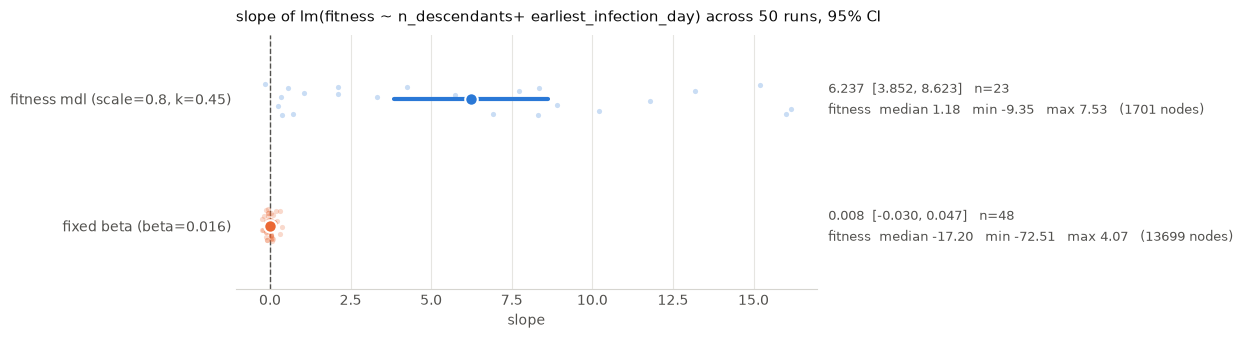

In [27]:
res_with_fitness = run_batch(evo_with_fitness)
ci_with_fitness = slope_ci(res_with_fitness["slope"])

res_without_fitness = run_batch(evo_without_fitness)
ci_without_fitness = slope_ci(res_without_fitness["slope"])

ax, st = plot_slope_ci(
    {f'fitness mdl (scale={FITNESS_SCALE}, k={K})': res_with_fitness, f'fixed beta (beta={BETA})': res_without_fitness},
    title=f'slope of lm(fitness ~ n_descendants+ earliest_infection_day) across {N} runs, 95% CI',
)
ax.figure.savefig(f"CI_k-{K}_scale-{FITNESS_SCALE}.png", dpi=200, bbox_inches="tight")  # save before show: plt.show() clears the figure
plt.show()